# 태양광 발전소 CSV 2종 + 서청주 ASOS CSV 프로파일링 (1차)

**목적:** 실제 고정식 발전소 두 곳과 서청주 ASOS 기상 CSV를 검사하여, 10개 가상 발전소 생성 **이전**에 데이터 구조·품질·시계열 정합성을 검증합니다. **가상 발전소 생성 / AI 학습 / OPC UA 연결은 이 노트북 범위 밖입니다.**

실행 환경: Python 3.10.20, pandas, numpy, matplotlib, Jupyter. PyTorch는 추후 모델 단계에서 사용하므로 이번 데이터 진단에는 필요하지 않습니다.

주요 원칙: (1) 원본 수정 금지 (2) 공백/NULL-only 열 탐지 및 분석용 사본에서 제외 (3) 날짜·결측·중복·간격 진단 (4) 발전소 A/B의 **실제 동일 시각** 중첩 진단 (5) ASOS 원본 시간의 의미를 임의 가정하지 않고 시간 단위 후보 매칭 진단 (6) 기상 변수 중 **허용된 연속형 변수만** 짧은 *내부* 결측을 오프라인 선형 보간하고 보간 플래그 보존.

**주의:** 15분 매칭은 아직 실제 시간별 기상관측을 15분 관측으로 간주하지 않습니다. 이 노트북에서는 시각 정합 *진단*만 수행합니다.

In [1]:
# 실행 환경 확인
import sys, os, re, csv, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('Python:', sys.version.split()[0], ' / pandas:', pd.__version__, ' / numpy:', np.__version__)


Python: 3.10.20  / pandas: 2.3.3  / numpy: 2.2.6


## 0. 입력 파일 및 분석 정책 설정

세 CSV의 실제 파일 경로만 변경하면 됩니다. 타임스탬프 컬럼을 자동 추정하지만, 잘못 인식하면 `timestamp_col`을 명시하십시오. **세 CSV 자체는 이번 대화에 첨부되지 않았으므로 실제 품질 수치가 아직 나오지 않습니다.**

- 시간은 모두 **한국표준시(KST)** 로 기록되었다는 가정이며, CSV 시각에 시간대가 없는 경우 원래 시각 문자열을 그대로 KST 시계열로 비교합니다. 서로 다른 시간대라면 사전 보정이 필요합니다.
- `TIME_ROUNDING`: 기본 `None` (인버터의 실제 시각 보존). 초 단위 편차가 확인되면 대응 방식부터 결정하십시오.
- 결측 보간: ASOS 시간축에서 **연속형 변수가 한두 시간 빠진 내부 결측에 한정**, 보간 이후에도 결측 여부를 기록합니다. 풍향/강수량/일사량/일조시간 등은 자동 보간에서 제외합니다.

In [2]:
# 사용자 설정 — 여기를 우선 수정하세요.
FILES = {
    'plant_A': {'path': os.getenv('CSV_PATH_A', '../assets/inverterdata/inverterdata_62_-261120.csv'), 'timestamp_col': None},
    'plant_B': {'path': os.getenv('CSV_PATH_B', '../assets/inverterdata/inverterdata_64_-261120.csv'), 'timestamp_col': None},
    'asos':    {'path': os.getenv('CSV_PATH_ASOS', '../assets/asosdata/asosdata.csv'), 'timestamp_col': None},
}
OUTPUT_DIR = Path(os.getenv('PROFILE_OUTPUT_DIR', './profile_output'))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
START = pd.Timestamp('2024-01-01 00:00:00')
END   = pd.Timestamp('2026-11-20 23:00:00')
EXPECTED_PLANT_FREQ = pd.Timedelta('15min')
EXPECTED_ASOS_FREQ = pd.Timedelta('1h')
MAX_ASOS_LINEAR_GAP_HOURS = 2   # 예비 기준; 결측 분포 확인 후 조정
MAX_ASOS_GRID_HOURS = 24 * 365 * 4  # 의도치 않은 거대 격자 생성 방지

print('설정된 경로:')
for k, v in FILES.items():
    p = Path(v['path'])
    print(f'  {k}: {p}  (존재={p.is_file()})')


설정된 경로:
  plant_A: ..\assets\inverterdata\inverterdata_62_-261120.csv  (존재=True)
  plant_B: ..\assets\inverterdata\inverterdata_64_-261120.csv  (존재=True)
  asos: ..\assets\asosdata\asosdata.csv  (존재=True)


## 1. 안전한 CSV 로드 및 컬럼 무효성 진단

UTF-8-SIG/UTF-8/CP949/EUC-KR, 일반적인 `,`/`;`/탭 구분자를 시도합니다. 대용량 파일도 우선 문자열로 읽어 **원본의 0, 코드값, 결측 표기**가 의도치 않게 바뀌지 않도록 합니다.

무효 열 정의: 공백 문자열 또는 `NULL`, `NaN`, `N/A`, `None` 등으로만 구성된 열. 숫자 0은 **유효값**이며, `-`는 기본적으로 **결측으로 자동 간주하지 않습니다**(고장코드 등에서 의미가 있을 수 있기 때문).

In [6]:
MISSING_STRINGS = {'', 'null', 'none', 'nan', 'n/a', 'na', '<null>'}
TIME_COLUMN_CANDIDATES = ['reg_date', 'regdate', 'timestamp', 'datetime', 'date_time',
                          'measured_at', 'time', '일시', '일자', '측정일시', '측정시간', '날짜']

def read_csv_robust(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'CSV 파일 없음: {path.resolve()}')
    attempts = []
    for enc in ['utf-8-sig', 'utf-8', 'cp949', 'euc-kr']:
        for sep in [',', '\t', ';']:
            try:
                df = pd.read_csv(path, encoding=enc, sep=sep, dtype='string',
                                 keep_default_na=False, low_memory=False)
                if df.shape[1] < 2:
                    continue
                print(f'[읽기 성공] {path.name} | encoding={enc}, sep={repr(sep)}, rows={len(df):,}, cols={len(df.columns)}')
                return df
            except (UnicodeDecodeError, pd.errors.ParserError, ValueError) as e:
                attempts.append(f'{enc}/{repr(sep)}:{type(e).__name__}')
    raise ValueError(f'CSV 읽기 실패: {path.name}; 시도={attempts[:8]} (인코딩/구분자 수동 확인)')

def normalize_missing_frame(raw):
    out = raw.copy()
    for c in out.columns:
        s = out[c].astype('string').str.strip()
        out[c] = s.mask(s.str.lower().isin(MISSING_STRINGS).fillna(False), pd.NA)
    return out

def column_profile(df, source_name):
    rows = []
    total = len(df)
    for c in df.columns:
        s = df[c]
        nonnull = int(s.notna().sum())
        rows.append({'dataset': source_name, 'column': c, 'rows': total,
                     'valid_count': nonnull, 'missing_count': total - nonnull,
                     'missing_pct': 100*(total-nonnull)/total if total else np.nan,
                     'distinct_nonnull': int(s.nunique(dropna=True)),
                     'all_missing': nonnull == 0,
                     'examples': ' | '.join(map(str, s.dropna().unique()[:3]))})
    return pd.DataFrame(rows)

def guess_time_column(columns, manual=None):
    if manual is not None:
        if manual not in columns:
            raise KeyError(f'설정한 시각 컬럼이 없음: {manual}; 실제 컬럼={list(columns)}')
        return manual
    norm = lambda s: re.sub(r'[\s_\-()]', '', str(s)).lower()
    matches = [c for c in columns if norm(c) in {norm(x) for x in TIME_COLUMN_CANDIDATES}]
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise ValueError(f'시각 컬럼 후보가 복수임: {matches}; FILES 설정에서 timestamp_col을 지정하세요.')
    raise ValueError(f'시각 컬럼 자동 식별 실패: {list(columns)}; FILES 설정에서 timestamp_col을 지정하세요.')

raw_frames, frames, profiles, time_cols = {}, {}, {}, {}
for name, spec in FILES.items():
    raw_frames[name] = read_csv_robust(spec['path'])
    normalized = normalize_missing_frame(raw_frames[name])
    profiles[name] = column_profile(normalized, name)
    invalid = profiles[name].loc[profiles[name]['all_missing'], 'column'].tolist()
    time_col = guess_time_column(normalized.columns, spec['timestamp_col'])
    if time_col in invalid:
        raise ValueError(f'{name}: 시각 컬럼이 전부 결측입니다: {time_col}')
    frames[name] = normalized.drop(columns=invalid).copy()
    time_cols[name] = time_col
    print(f'[{name}] 시각 컬럼={time_col!r}; 전부 결측 컬럼({len(invalid)}개)={invalid}')

column_reports = pd.concat(profiles.values(), ignore_index=True)
column_reports.to_csv(OUTPUT_DIR / '01_column_profile.csv', index=False, encoding='utf-8-sig')
pd.set_option("display.max_rows", None)  # 전체 행 출력
pd.set_option("display.max_columns", None)  # 전체 열 출력
display(column_reports)


[읽기 성공] inverterdata_62_-261120.csv | encoding=utf-8-sig, sep=',', rows=227,458, cols=19
[plant_A] 시각 컬럼='reg_date'; 전부 결측 컬럼(0개)=[]
[읽기 성공] inverterdata_64_-261120.csv | encoding=utf-8-sig, sep=',', rows=213,722, cols=19
[plant_B] 시각 컬럼='reg_date'; 전부 결측 컬럼(0개)=[]
[읽기 성공] asosdata.csv | encoding=cp949, sep=',', rows=25,320, cols=20
[asos] 시각 컬럼='일시'; 전부 결측 컬럼(0개)=[]


,dataset,column,rows,valid_count,missing_count,missing_pct,distinct_nonnull,all_missing,examples
0,plant_A,sid,227458,227458,0,0.000000,1,False,62
1,plant_A,deviceID,227458,227458,0,0.000000,1,False,1
2,plant_A,multiID,227458,227458,0,0.000000,1,False,1
3,plant_A,errcode,227458,227458,0,0.000000,2,False,0 | 57
4,plant_A,pv_v,227458,227458,0,0.000000,525,False,0 | 511 | 518
5,plant_A,pv_i,227458,227458,0,0.000000,105,False,0 | 69 | 66
6,plant_A,pv_output,227458,227458,0,0.000000,4764,False,0 | 35550 | 35960
7,plant_A,sys_r_v,227458,227458,0,0.000000,35,False,0 | 231 | 232
8,plant_A,sys_s_v,227458,227458,0,0.000000,38,False,0 | 229 | 228
9,plant_A,sys_t_v,227458,227458,0,0.000000,37,False,0 | 229 | 228


## 2. 시각 파싱, 중복/정렬/간격/결측 구간 검사

잘못된 시각은 임의 보정하지 않습니다. 결측 시각 또는 중복 시각은 별도 보고하고, 15분 정합 검사는 **정확한 15분 격자(00/15/30/45분)** 기반으로 수행합니다. 원본 시각은 `_source_timestamp_text`에 보존합니다.

In [7]:
def parse_times(series):
    clean = series.astype('string').str.strip()
    # 여러 형식의 날짜 문자열 허용. timezone-aware 값이 섞인 경우 별도 정규화 필요.
    try:
        return pd.to_datetime(clean, errors='coerce', format='mixed')
    except (TypeError, ValueError):
        return pd.to_datetime(clean, errors='coerce')

def gap_runs_from_index(dt_index, freq, max_range=None):
    idx = pd.DatetimeIndex(dt_index).dropna().sort_values().unique()
    if not len(idx):
        return pd.DataFrame(columns=['start','end','missing_steps'])
    start, end = idx.min(), idx.max()
    if max_range and (end-start) > max_range:
        raise ValueError('시간축 범위가 비정상적으로 깁니다. 시각 파싱을 확인하세요.')
    expected = pd.date_range(start=start.ceil(freq), end=end.floor(freq), freq=freq)
    missing = expected.difference(idx)
    if len(missing) == 0:
        return pd.DataFrame(columns=['start','end','missing_steps'])
    breaks = missing.to_series().diff().ne(freq).cumsum()
    out=[]
    for _, group in missing.to_series().groupby(breaks):
        out.append({'start':group.iloc[0], 'end':group.iloc[-1], 'missing_steps':len(group)})
    return pd.DataFrame(out)

validated = {}
summary_rows=[]
for name, frame in frames.items():
    f = frame.copy()
    f['_source_timestamp_text'] = f[time_cols[name]]
    f['_timestamp'] = parse_times(f[time_cols[name]])
    if getattr(f['_timestamp'].dt, 'tz', None) is not None:
        raise ValueError(f'{name}: 시간대 포함 시각입니다. KST 변환 기준을 확정한 뒤 실행하세요.')
    freq = EXPECTED_ASOS_FREQ if name == 'asos' else EXPECTED_PLANT_FREQ
    nonnull_ts = f['_timestamp'].dropna()
    duplicate_mask = f['_timestamp'].notna() & f['_timestamp'].duplicated(keep=False)
    aligned_mask = (f['_timestamp'].notna() &
                    f['_timestamp'].dt.floor(freq).eq(f['_timestamp']))
    gaps = gap_runs_from_index(nonnull_ts, freq, pd.Timedelta(days=365*5))
    gaps.to_csv(OUTPUT_DIR / f'02_{name}_missing_timestamp_runs.csv', index=False, encoding='utf-8-sig')
    # 다른 값이지만 같은 시각에 중복된 데이터는 우선 남기고 보고만 함
    f.loc[duplicate_mask].to_csv(OUTPUT_DIR / f'02_{name}_duplicate_timestamps.csv', index=False, encoding='utf-8-sig')
    validated[name] = f
    summary_rows.append({'dataset':name, 'rows':len(f), 'time_col':time_cols[name],
       'invalid_timestamps':int(f['_timestamp'].isna().sum()),
       'duplicate_rows_by_timestamp':int(duplicate_mask.sum()),
       'not_on_expected_grid':int((f['_timestamp'].notna() & ~aligned_mask).sum()),
       'start':nonnull_ts.min(), 'end':nonnull_ts.max(),
       'missing_grid_timestamps':int(gaps['missing_steps'].sum()) if len(gaps) else 0,
       'longest_missing_run':int(gaps['missing_steps'].max()) if len(gaps) else 0,
       'unique_timestamps':int(nonnull_ts.nunique())})

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUTPUT_DIR / '02_time_summary.csv', index=False, encoding='utf-8-sig')
display(summary)


,dataset,rows,time_col,invalid_timestamps,duplicate_rows_by_timestamp,not_on_expected_grid,start,end,missing_grid_timestamps,longest_missing_run,unique_timestamps
0,plant_A,227458,reg_date,0,28,212048,2022-07-14 17:02:00,2026-11-20 17:31:00,137232,665,227441
1,plant_B,213722,reg_date,0,34,199183,2024-05-24 16:09:00,2026-11-20 17:38:00,72827,6560,213705
2,asos,25320,일시,0,0,0,2024-01-01 00:00:00,2026-11-20 23:00:00,0,0,25320


## 3. 두 실측 발전소 및 ASOS 시각 겹침 진단

A/B의 공통 실측 15분 시각을 계산하고, ASOS는 **같은 시각(정각)** 및 **시간 내 후보 매핑** 둘 다 보고합니다. 후자는 표본 정합률을 보기 위한 비교용이지 기상 관측값을 각 15분에 복제했다는 의미가 아닙니다.

인버터의 시각이 수집 시각인지 관측 구간 종료 시각인지, ASOS의 항목별 관측 시각이 순간값인지 이전 시간의 집계값인지 확인하기 전까지 최종 1:1 결합은 보류합니다.

In [8]:
def unique_good_times(name, freq):
    x = validated[name]['_timestamp'].dropna()
    return pd.DatetimeIndex(x.loc[x.eq(x.dt.floor(freq))].unique()).sort_values()

a_times = unique_good_times('plant_A', EXPECTED_PLANT_FREQ)
b_times = unique_good_times('plant_B', EXPECTED_PLANT_FREQ)
w_times = unique_good_times('asos', EXPECTED_ASOS_FREQ)
common_ab = a_times.intersection(b_times)
common_all_exact = common_ab.intersection(w_times)
# 후보 접근: 분/초를 떼고 같은 '시(時)' 기상 레코드가 있는지 확인
common_ab_hour = pd.DatetimeIndex(common_ab.floor('h'))
common_hour_present = np.asarray(common_ab_hour.isin(w_times))
match_summary = pd.DataFrame([{
    'plant_A_unique_15min':len(a_times), 'plant_B_unique_15min':len(b_times),
    'plant_A_B_common':len(common_ab),
    'plant_A_B_common_pct_of_A':round(100*len(common_ab)/len(a_times),2) if len(a_times) else np.nan,
    'plant_A_B_common_pct_of_B':round(100*len(common_ab)/len(b_times),2) if len(b_times) else np.nan,
    'A_B_ASOS_exact_hour_count':len(common_all_exact),
    'A_B_ASOS_same_hour_candidate_count':int(common_hour_present.sum()),
    'A_B_ASOS_same_hour_candidate_pct':round(100*common_hour_present.mean(),2) if len(common_hour_present) else np.nan
}])
match_summary.to_csv(OUTPUT_DIR / '03_timestamp_overlap_summary.csv', index=False, encoding='utf-8-sig')
display(match_summary)

matched_index = pd.DataFrame({'timestamp_15min':common_ab})
matched_index['asos_hour_candidate'] = matched_index['timestamp_15min'].dt.floor('h')
matched_index['asos_hour_exists'] = matched_index['asos_hour_candidate'].isin(w_times)
matched_index.to_csv(OUTPUT_DIR / '03_common_plant_timestamps_and_asos_hour_candidate.csv',index=False,encoding='utf-8-sig')
print('원본 2개 발전소의 공통 15분 시각 표본:')
display(matched_index.head(10))


,plant_A_unique_15min,plant_B_unique_15min,plant_A_B_common,plant_A_B_common_pct_of_A,plant_A_B_common_pct_of_B,A_B_ASOS_exact_hour_count,A_B_ASOS_same_hour_candidate_count,A_B_ASOS_same_hour_candidate_pct
0,15410,14539,1482,9.62,10.19,374,1482,100.0


원본 2개 발전소의 공통 15분 시각 표본:


,timestamp_15min,asos_hour_candidate,asos_hour_exists
0,2024-05-26 06:00:00,2024-05-26 06:00:00,True
1,2024-05-26 06:15:00,2024-05-26 06:00:00,True
2,2024-05-26 06:30:00,2024-05-26 06:00:00,True
3,2024-05-26 06:45:00,2024-05-26 06:00:00,True
4,2024-05-26 07:00:00,2024-05-26 07:00:00,True
5,2024-05-26 07:15:00,2024-05-26 07:00:00,True
6,2024-05-26 07:30:00,2024-05-26 07:00:00,True
7,2024-05-27 08:15:00,2024-05-27 08:00:00,True
8,2024-05-27 08:30:00,2024-05-27 08:00:00,True
9,2024-05-27 09:00:00,2024-05-27 09:00:00,True


## 4. ASOS 변수별 결측 분석 + 제한적 선형 보간 (오프라인 실험)

이번 단계는 **시간별 원본 자료의 결측을 먼저 보완**합니다. 15분 변환은 하지 않습니다.

- **자동 보간 허용:** 기온, 기압, 상대습도, 이슬점온도 같은 연속형 항목(실제 컬럼명 확인 후 필요시 수정)
- **자동 보간 제외:** 풍향(원형 변수), 풍속(급변 가능), 강수량, 일사량, 일조시간, 운량, 시정 등
- 연속 결측이 최대 2시간인 **양 끝 관측값이 있는 내부 구간**만 보간합니다. 외삽은 금지합니다.
- 긴 결측이 남은 시점은 결측으로 유지합니다. 품질 플래그에서 불량으로 정의된 값은 실제 코드북 확인 후 결측으로 변환해야 합니다.
- ASOS가 관측 전체 기간을 벗어나더라도 목표 분석 기간 내로 제한해 검사합니다. 원본 CSV는 바꾸지 않습니다.

In [9]:
# 허용 목록: 실제 컬럼에 대응되는 패턴만 선택합니다. 기압 항목은 컬럼 정의 확인 필요.
ASOS_CONTINUOUS_PATTERNS = [
    r'^기온', r'^기압', r'^현지기압', r'^해면기압', r'^상대습도', r'^이슬점온도',
    r'^기온\(', r'^기압\(', r'^상대습도\(', r'^이슬점온도\('
]
ASOS_NEVER_INTERPOLATE_PATTERNS = [
    r'풍향', r'풍속', r'강수', r'일사', r'일조', r'운량', r'시정', r'적설',
    r'지점', r'품질', r'qc', r'코드', r'현상'
]

def allowed_numeric_weather_columns(df, time_col):
    selected=[]; reasons=[]
    for c in df.columns:
        if c in {time_col, '_timestamp', '_source_timestamp_text'}: continue
        if any(re.search(p,c,re.I) for p in ASOS_NEVER_INTERPOLATE_PATTERNS):
            reasons.append((c,'excluded_variable_type')); continue
        if any(re.search(p,c,re.I) for p in ASOS_CONTINUOUS_PATTERNS):
            v=pd.to_numeric(df[c].str.replace(',','',regex=False), errors='coerce')
            if v.notna().any(): selected.append(c)
            else: reasons.append((c,'not_numeric_or_all_missing'))
        else:
            reasons.append((c,'not_in_allowlist'))
    return selected, reasons

asos = validated['asos'].copy()
asos = asos.loc[asos['_timestamp'].between(START,END)].copy()
if asos['_timestamp'].duplicated().any():
    # 중복된 시각을 임의 평균하지 않음
    raise ValueError('ASOS에 중복 시각이 있습니다. 02_asos_duplicate_timestamps.csv 확인 후 중복 정책을 먼저 결정하세요.')
asos = asos.loc[asos['_timestamp'].notna()]
if asos.empty:
    raise ValueError('설정한 분석 기간에 ASOS 시각이 없습니다.')
asos = asos.set_index('_timestamp').sort_index()
weather_cols, excluded_cols = allowed_numeric_weather_columns(asos.reset_index(),time_cols['asos'])
print('선형 보간 대상:', weather_cols)
print('보간 제외 컬럼 일부:', excluded_cols[:20])

# 목표 기간의 시간별 격자. 원본에 없는 시간도 결측으로 표기.
hourly_index = pd.date_range(START, END, freq='h')
if len(hourly_index) > MAX_ASOS_GRID_HOURS:
    raise ValueError('ASOS 시간 격자가 너무 큽니다. START/END 확인.')
asos_numeric = pd.DataFrame(index=hourly_index)
for c in weather_cols:
    series = pd.to_numeric(asos[c].str.replace(',','',regex=False), errors='coerce')
    asos_numeric[c] = series.reindex(hourly_index)

# 보간 가능한 결측은 반드시 좌우 측정값이 있고 길이가 임계치 이하인 구간만.
def interpolate_short_internal_gaps(series, max_gap=2):
    s = series.astype(float)
    na=s.isna()
    grp=(na != na.shift(fill_value=False)).cumsum()
    sizes=na.groupby(grp).transform('sum')
    # 결측 구간 앞뒤 경계가 유효한지 확인; 시계열 경계 부분 보간 방지
    pos=np.arange(len(s))
    valid_positions=np.flatnonzero(s.notna().to_numpy())
    if len(valid_positions)<2:
        return s.copy(), pd.Series(False,index=s.index)
    internal = pd.Series((pos>valid_positions[0]) & (pos<valid_positions[-1]), index=s.index)
    fillable=na & internal & sizes.le(max_gap)
    candidate=s.interpolate(method='time', limit_area='inside')
    result=s.where(~fillable, candidate)
    flag=fillable & result.notna()
    return result,flag

filled_hourly=asos_numeric.copy()
interp_report=[]
for c in weather_cols:
    filled_hourly[c],flag=interpolate_short_internal_gaps(asos_numeric[c],MAX_ASOS_LINEAR_GAP_HOURS)
    filled_hourly[c+'__was_interpolated']=flag.astype('boolean')
    interp_report.append({'column':c,'missing_before':int(asos_numeric[c].isna().sum()),
       'filled_short_internal':int(flag.sum()),
       'missing_after':int(filled_hourly[c].isna().sum()),
       'fill_pct_of_missing':round(100*flag.sum()/asos_numeric[c].isna().sum(),2) if asos_numeric[c].isna().sum() else 0})

# 습도는 반드시 물리 범위 검증: 비정상 값이 원본에 있으면 보간 전에 품질 검토가 필요.
for c in weather_cols:
    if '습도' in c:
        invalid=filled_hourly[c].notna() & ~filled_hourly[c].between(0,100)
        if invalid.any():
            warnings.warn(f'{c}: 0~100 범위 밖 {invalid.sum()}건. 해당 값을 별도 검토하세요.')

interpolation_report=pd.DataFrame(interp_report)
interpolation_report.to_csv(OUTPUT_DIR/'04_asos_linear_interpolation_report.csv',index=False,encoding='utf-8-sig')
filled_hourly.index.name='asos_hour'
filled_hourly.to_csv(OUTPUT_DIR/'04_asos_hourly_continuous_interpolated.csv',encoding='utf-8-sig')
display(interpolation_report)


선형 보간 대상: ['기온(°C)', '이슬점온도(°C)', '현지기압(hPa)', '해면기압(hPa)']
보간 제외 컬럼 일부: [('지점', 'excluded_variable_type'), ('지점명', 'excluded_variable_type'), ('강수량(mm)', 'excluded_variable_type'), ('풍속(m/s)', 'excluded_variable_type'), ('풍향(16방위)', 'excluded_variable_type'), ('습도(%)', 'not_in_allowlist'), ('증기압(hPa)', 'not_in_allowlist'), ('일조(hr)', 'excluded_variable_type'), ('일사(MJ/m2)', 'excluded_variable_type'), ('적설(cm)', 'excluded_variable_type'), ('전운량(10분위)', 'excluded_variable_type'), ('중하층운량(10분위)', 'excluded_variable_type'), ('최저운고(100m )', 'not_in_allowlist'), ('시정(10m)', 'excluded_variable_type'), ('지면온도(°C)', 'not_in_allowlist')]


,column,missing_before,filled_short_internal,missing_after,fill_pct_of_missing
0,기온(°C),17,9,8,52.94
1,이슬점온도(°C),17,9,8,52.94
2,현지기압(hPa),15,7,8,46.67
3,해면기압(hPa),17,9,8,52.94


## 5. 시계열/결측 시각화 및 핵심 진단 요약

ASOS 결측 보간 전/후(선별된 첫 연속형 컬럼) 및 각 데이터의 날짜별 레코드 수를 확인합니다. 출력이 지나치게 크지 않게 그림만 표시합니다.

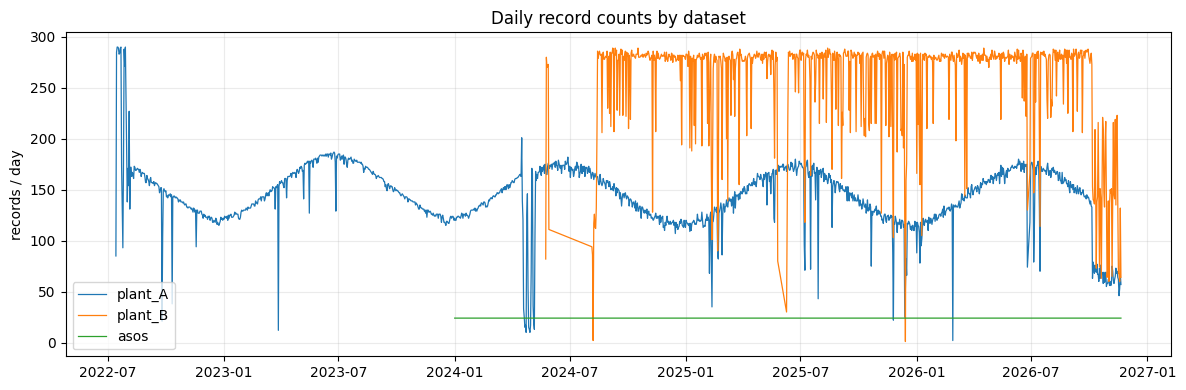

C:\Users\USER\AppData\Local\Temp\ipykernel_279796\3612827617.py:18: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  ax.legend(); ax.grid(alpha=.25);plt.tight_layout();plt.show()
C:\Users\USER\AppData\Local\Temp\ipykernel_279796\3612827617.py:18: UserWarning: Glyph 50728 (\N{HANGUL SYLLABLE ON}) missing from font(s) DejaVu Sans.
  ax.legend(); ax.grid(alpha=.25);plt.tight_layout();plt.show()
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50728 (\N{HANGUL SYLLABLE ON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


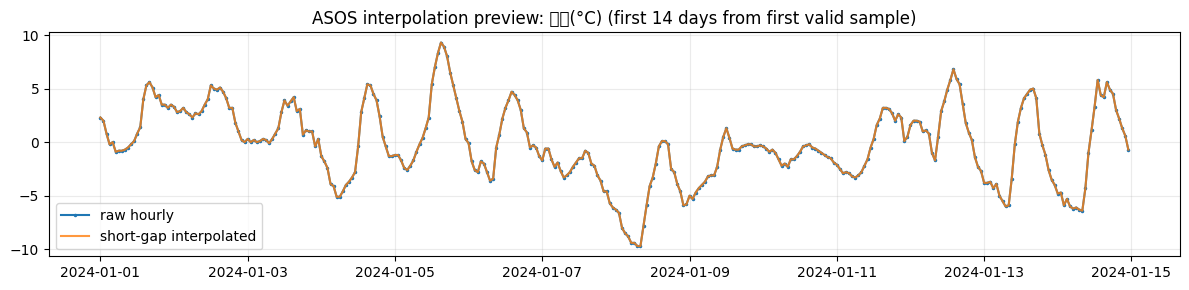

출력 경로: D:\KKW\_Repository\VSCode\github\CBNU.Master.1yr.intelIoT\termproj\llm_suggest\profile_output
핵심 진단:
 - 전체 무효 컬럼 수: 0
 - 두 발전소 공통 유효 15분 시각 수: 1482
 - 시간별 ASOS가 존재하는 공통 발전소 시각 수 (같은 시 후보): 1482
 - ASOS 선형 보간 대상 변수 수: 4


In [10]:
fig, ax = plt.subplots(figsize=(12,4))
for name in ['plant_A','plant_B','asos']:
    f=validated[name]
    daily=f.dropna(subset=['_timestamp']).groupby(f['_timestamp'].dt.floor('D')).size()
    ax.plot(daily.index,daily.values,label=name,linewidth=0.9)
ax.set_title('Daily record counts by dataset')
ax.set_ylabel('records / day')
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
if weather_cols:
    c=weather_cols[0]
    sample=asos_numeric.loc[asos_numeric[c].first_valid_index():,c].head(24*14)
    if len(sample):
        fig,ax=plt.subplots(figsize=(12,3))
        ax.plot(sample.index,sample.values,marker='.',ms=3,label='raw hourly')
        ax.plot(filled_hourly.loc[sample.index].index,filled_hourly.loc[sample.index,c].values,
                label='short-gap interpolated',alpha=.8)
        ax.set_title(f'ASOS interpolation preview: {c} (first 14 days from first valid sample)')
        ax.legend(); ax.grid(alpha=.25);plt.tight_layout();plt.show()
print('출력 경로:',OUTPUT_DIR.resolve())
print('핵심 진단:')
print(' - 전체 무효 컬럼 수:',int(column_reports['all_missing'].sum()))
print(' - 두 발전소 공통 유효 15분 시각 수:',len(common_ab))
print(' - 시간별 ASOS가 존재하는 공통 발전소 시각 수 (같은 시 후보):',int(common_hour_present.sum()))
print(' - ASOS 선형 보간 대상 변수 수:',len(weather_cols))


## 6. 결과 파일 및 다음 단계

`profile_output/` 폴더에 다음 파일이 생성됩니다.

- `01_column_profile.csv`: 전체 컬럼, 결측 비율, NULL-only 열, 고유값 수
- `02_time_summary.csv`: 시각 파싱 실패, 중복, 정시/15분 격자 불일치, 결측 개수
- `02_*_missing_timestamp_runs.csv`: 연속 시각 결측 시작/종료 및 길이
- `02_*_duplicate_timestamps.csv`: 중복 레코드 보존·검토
- `03_timestamp_overlap_summary.csv`: 발전소 A/B 공통 실측 시각 및 ASOS 시간별 후보 매칭
- `03_common_plant_timestamps_and_asos_hour_candidate.csv`: 각 공통 시각의 대응 ASOS 정각 후보 및 존재 여부
- `04_asos_linear_interpolation_report.csv`: 변수별 선형 보간 전후 결측 수
- `04_asos_hourly_continuous_interpolated.csv`: 허용된 연속형 ASOS 변수의 시간별 보간 데이터 + 보간 플래그

**다음 단계(별도 노트북):** 실제 CSV의 컬럼/단위를 확인한 뒤 ASOS 15분 변환 정책(순간값·시간 집계량별 처리)과 공통 시각 기반 10개 가상 발전소 생성 규칙을 확정합니다. 결측 보간된 데이터를 정상 관측으로 오인하지 않도록 플래그를 유지합니다.
